Using device: cpu

       TRAINING MODEL A (Standard CNN)
Epoch [01/20] - Train Loss: 1.4302, Train Acc: 0.4453 | Val Loss: 1.0155, Val Acc: 0.6069
Epoch [02/20] - Train Loss: 1.0653, Train Acc: 0.5832 | Val Loss: 0.9808, Val Acc: 0.6051
Epoch [03/20] - Train Loss: 1.0068, Train Acc: 0.5995 | Val Loss: 0.9009, Val Acc: 0.6746
Epoch [04/20] - Train Loss: 0.9502, Train Acc: 0.6256 | Val Loss: 0.8711, Val Acc: 0.6746
Epoch [05/20] - Train Loss: 0.9076, Train Acc: 0.6459 | Val Loss: 0.9676, Val Acc: 0.6618
Epoch [06/20] - Train Loss: 0.8329, Train Acc: 0.6747 | Val Loss: 0.8044, Val Acc: 0.7020
Epoch [07/20] - Train Loss: 0.7587, Train Acc: 0.7067 | Val Loss: 0.7697, Val Acc: 0.7185
Epoch [08/20] - Train Loss: 0.7580, Train Acc: 0.6989 | Val Loss: 0.8245, Val Acc: 0.7112
Epoch [09/20] - Train Loss: 0.7017, Train Acc: 0.7308 | Val Loss: 0.7519, Val Acc: 0.7404
Epoch [10/20] - Train Loss: 0.6385, Train Acc: 0.7526 | Val Loss: 0.7526, Val Acc: 0.7331
Epoch [11/20] - Train Loss: 0.6269, Train 

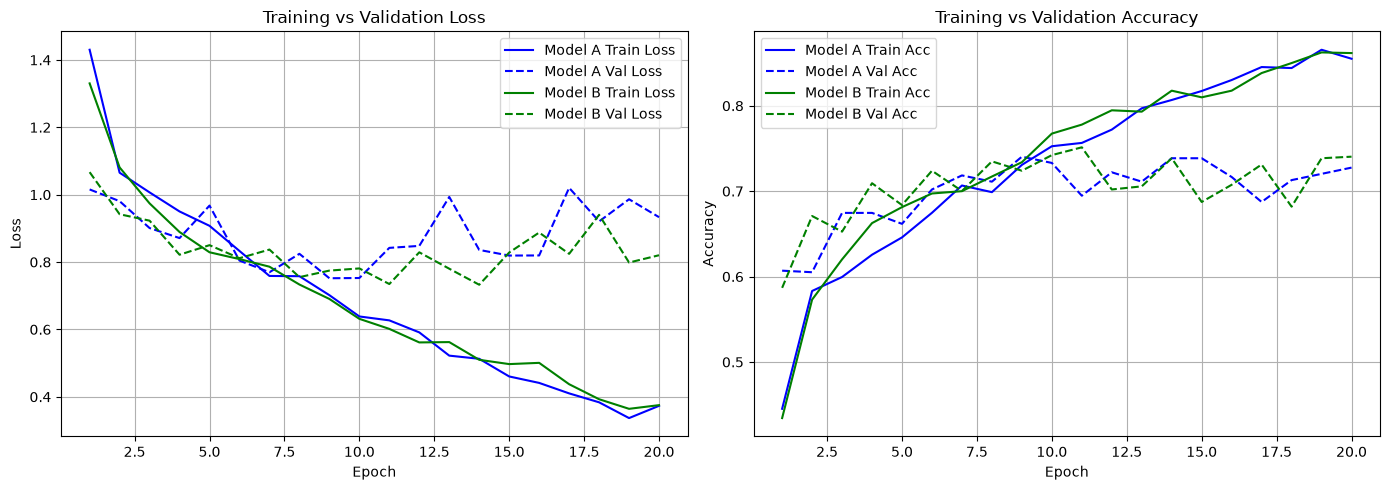


Metric                         | Model A (Standard) | Model B (Lightweight)
Total Parameters               | 1,143,045          | 41,413            
Disk Size (KB)                 | 4475.18            | 173.80            
Time / Epoch (s)               | 9.050              | 4.909             
Test Accuracy                  | 70.68            % | 67.63            %
Model parameters successfully saved to c:\Users\Sithum Peiris\Documents\GitHub\CNN-to-perform-classification\saved_models!


In [1]:
import os
import sys
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Add project root to sys.path so 'models' and 'utils' imports work cleanly
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

# ---------------------------------------------------------
# 1. Device Setup & Data Loaders
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Preprocessing pipeline
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

TRAIN_DIR = os.path.join(PROJECT_ROOT, "data", "train")
VAL_DIR = os.path.join(PROJECT_ROOT, "data", "val")
TEST_DIR = os.path.join(PROJECT_ROOT, "data", "test")

train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=transform)
val_dataset = datasets.ImageFolder(root=VAL_DIR, transform=transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# ---------------------------------------------------------
# 2. Training Loop Function
# ---------------------------------------------------------
def train_and_validate(model, train_loader, val_loader, criterion, optimizer, epochs=20):
    model.to(device)
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    
    start_time = time.time()

    for epoch in range(epochs):
        # Training Phase
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / len(train_dataset)
        epoch_train_acc = correct / total
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc)

        # Validation Phase
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        epoch_val_loss = val_loss / len(val_dataset)
        epoch_val_acc = val_correct / val_total
        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc)

        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] - "
              f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

    total_time = time.time() - start_time
    avg_epoch_time = total_time / epochs
    
    return {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accs': train_accs,
        'val_accs': val_accs,
        'avg_epoch_time': avg_epoch_time
    }

# ---------------------------------------------------------
# 3. Test Evaluation Function
# ---------------------------------------------------------
def evaluate_test(model, test_loader):
    model.eval()
    model.to(device)
    correct, total = 0, 0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    test_accuracy = correct / total
    return test_accuracy, np.array(all_preds), np.array(all_labels)

# Helper function to compute file size on disk in KB
def get_model_disk_size_kb(model, filename="temp_model.pth"):
    torch.save(model.state_dict(), filename)
    size_bytes = os.path.getsize(filename)
    os.remove(filename)
    return size_bytes / 1024.0

# ---------------------------------------------------------
# 4. Train Model A & Model B (Adam Optimizer)
# ---------------------------------------------------------
criterion = nn.CrossEntropyLoss()

print("\n==========================================")
print("       TRAINING MODEL A (Standard CNN)")
print("==========================================")
model_a = ModelA(num_classes=5)
optimizer_a = optim.Adam(model_a.parameters(), lr=0.001)
history_a = train_and_validate(model_a, train_loader, val_loader, criterion, optimizer_a, epochs=20)
test_acc_a, _, _ = evaluate_test(model_a, test_loader)
params_a = sum(p.numel() for p in model_a.parameters() if p.requires_grad)
disk_size_a = get_model_disk_size_kb(model_a)

print("\n==========================================")
print("   TRAINING MODEL B (Lightweight Depthwise)")
print("==========================================")
model_b = ModelB(num_classes=5)
optimizer_b = optim.Adam(model_b.parameters(), lr=0.001)
history_b = train_and_validate(model_b, train_loader, val_loader, criterion, optimizer_b, epochs=20)
test_acc_b, _, _ = evaluate_test(model_b, test_loader)
params_b = sum(p.numel() for p in model_b.parameters() if p.requires_grad)
disk_size_b = get_model_disk_size_kb(model_b)

# ---------------------------------------------------------
# 5. Plot Loss & Accuracy Curves (Section 4 Requirement)
# ---------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Loss Plot
axs[0].plot(range(1, 21), history_a['train_losses'], 'b-', label='Model A Train Loss')
axs[0].plot(range(1, 21), history_a['val_losses'], 'b--', label='Model A Val Loss')
axs[0].plot(range(1, 21), history_b['train_losses'], 'g-', label='Model B Train Loss')
axs[0].plot(range(1, 21), history_b['val_losses'], 'g--', label='Model B Val Loss')
axs[0].set_title('Training vs Validation Loss')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Loss')
axs[0].legend()
axs[0].grid(True)

# Accuracy Plot
axs[1].plot(range(1, 21), history_a['train_accs'], 'b-', label='Model A Train Acc')
axs[1].plot(range(1, 21), history_a['val_accs'], 'b--', label='Model A Val Acc')
axs[1].plot(range(1, 21), history_b['train_accs'], 'g-', label='Model B Train Acc')
axs[1].plot(range(1, 21), history_b['val_accs'], 'g--', label='Model B Val Acc')
axs[1].set_title('Training vs Validation Accuracy')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Accuracy')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.savefig('custom_models_training_curves.png')
plt.show()

# ---------------------------------------------------------
# 6. Summary Comparison Table (Section 4 Requirement)
# ---------------------------------------------------------
print("\n" + "="*70)
print(f"{'Metric':<30} | {'Model A (Standard)':<18} | {'Model B (Lightweight)':<18}")
print("="*70)
print(f"{'Total Parameters':<30} | {params_a:<18,} | {params_b:<18,}")
print(f"{'Disk Size (KB)':<30} | {disk_size_a:<18.2f} | {disk_size_b:<18.2f}")
print(f"{'Time / Epoch (s)':<30} | {history_a['avg_epoch_time']:<18.3f} | {history_b['avg_epoch_time']:<18.3f}")
print(f"{'Test Accuracy':<30} | {test_acc_a*100:<17.2f}% | {test_acc_b*100:<17.2f}%")
print("="*70)

# 1. Create directory for weights
weights_dir = os.path.join(PROJECT_ROOT, "saved_models")
os.makedirs(weights_dir, exist_ok=True)

# 2. Save state dictionaries
torch.save(model_a.state_dict(), os.path.join(weights_dir, "model_a_weights.pth"))
torch.save(model_b.state_dict(), os.path.join(weights_dir, "model_b_weights.pth"))

print(f"Model parameters successfully saved to {weights_dir}!")

Loaded Model A weights successfully.
Loaded Model B weights successfully.
Generating class activation templates for Model A...
Generating class activation templates for Model B...


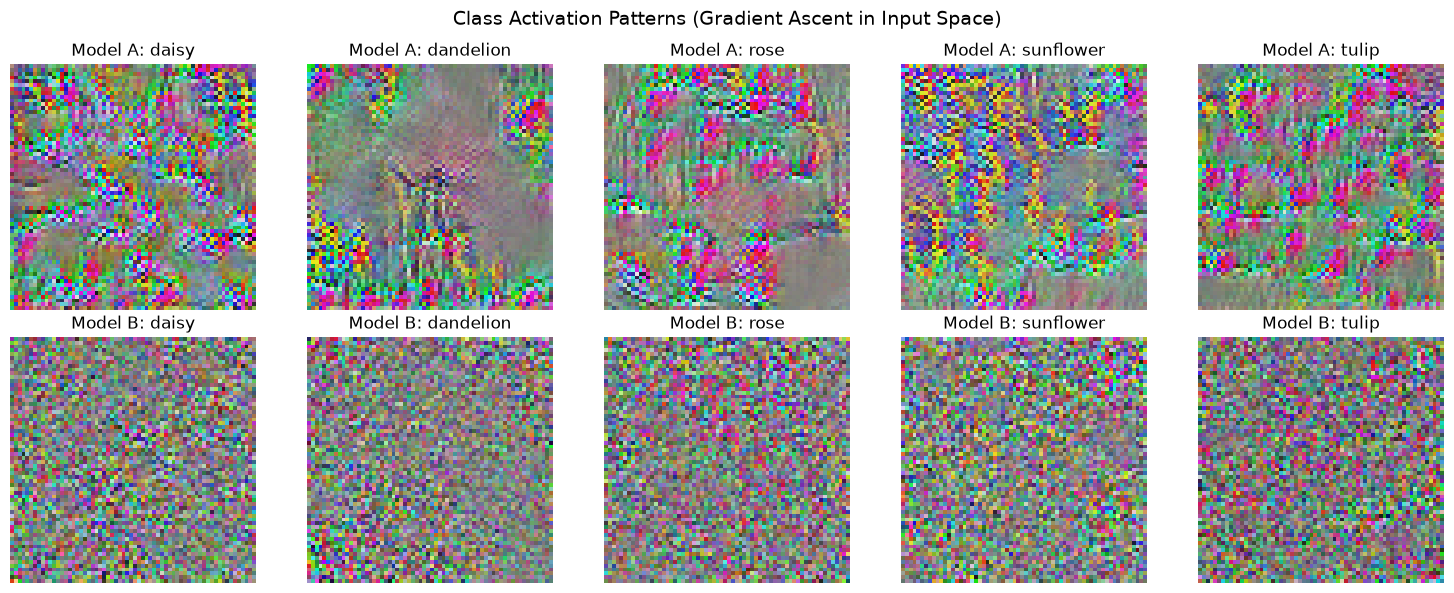

In [5]:
import os
import sys
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Path resolution so models can be imported from any location
CURRENT_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(CURRENT_DIR, ".."))

if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

def generate_class_template(model, target_class_idx, steps=300, lr=0.05, device='cpu'):
    """
    Performs Gradient Ascent starting from random noise to generate an image
    that maximally activates a target class in the given model.
    """
    model.eval()
    model.to(device)

    # Start with random noise image (1, 3, 64, 64)
    input_img = torch.randn(1, 3, 64, 64, device=device, requires_grad=True)
    optimizer = torch.optim.Adam([input_img], lr=lr)

    for step in range(steps):
        optimizer.zero_grad()
        output = model(input_img)
        
        # Loss is negative logits for the target class (gradient ascent minimizes this)
        loss = -output[0, target_class_idx]
        loss.backward()
        optimizer.step()

    # Post-process tensor back to RGB viewable image [0, 1]
    img = input_img.squeeze(0).detach().cpu().numpy()
    img = np.transpose(img, (1, 2, 0))
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)  # Normalize
    return img

def show_both_models_class_templates(model_a, model_b, class_names=['daisy', 'dandelion', 'rose', 'sunflower', 'tulip'], device='cpu'):
    """
    Generates and plots class activation templates for Model A and Model B side-by-side.
    """
    fig, axs = plt.subplots(2, 5, figsize=(15, 6))

    print("Generating class activation templates for Model A...")
    for idx, name in enumerate(class_names):
        template_a = generate_class_template(model_a, target_class_idx=idx, device=device)
        axs[0, idx].imshow(template_a)
        axs[0, idx].set_title(f"Model A: {name}")
        axs[0, idx].axis('off')

    print("Generating class activation templates for Model B...")
    for idx, name in enumerate(class_names):
        template_b = generate_class_template(model_b, target_class_idx=idx, device=device)
        axs[1, idx].imshow(template_b)
        axs[1, idx].set_title(f"Model B: {name}")
        axs[1, idx].axis('off')

    plt.suptitle("Class Activation Patterns (Gradient Ascent in Input Space)", fontsize=14)
    plt.tight_layout()
    plt.savefig('class_activation_templates.png')
    plt.show()

# --- Execution Block ---
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 1. Instantiate models
    model_a = ModelA(num_classes=5)
    model_b = ModelB(num_classes=5)

    # 2. Locate saved weight files
    weights_a_path = os.path.join(PROJECT_ROOT, "saved_models", "model_a_weights.pth")
    weights_b_path = os.path.join(PROJECT_ROOT, "saved_models", "model_b_weights.pth")

    # 3. Load saved weights
    if os.path.exists(weights_a_path):
        model_a.load_state_dict(torch.load(weights_a_path, map_location=device))
        print("Loaded Model A weights successfully.")
    else:
        print(f"Warning: Model A weights not found at '{weights_a_path}'. Using untrained weights.")

    if os.path.exists(weights_b_path):
        model_b.load_state_dict(torch.load(weights_b_path, map_location=device))
        print("Loaded Model B weights successfully.")
    else:
        print(f"Warning: Model B weights not found at '{weights_b_path}'. Using untrained weights.")

    # 4. Generate and display templates
    show_both_models_class_templates(model_a, model_b, device=device)